# Módulo 1 — Punto 1.3: Detección de Bordes y Dominio Frecuencial

**Objetivo:** encontrar el contorno de la pupila con operadores de borde y
entender la imagen como una suma de ondas (Transformada de Fourier 2D): qué
información guarda la magnitud y cuál la fase, cómo se reparte la energía
(PSD) y cómo filtrar directamente en frecuencia.

**Todo el código está en este notebook.** Lo único que se lee de afuera es
`config.yaml` (ruta de la imagen/video y la ROI), para usar el mismo recorte
que en 1.1 y 1.2. Los parámetros propios del 1.3 están en la celda
**Parámetros**.

## 0. Preparación: librerías, parámetros, imagen y ROI
Abrimos el archivo de config, la imagen, la pasamos a escala de grises y hacemos el ROI como en los otros puntos.

In [25]:
import sys
from pathlib import Path             # manejo de rutas (Windows/Linux/Mac por igual)

# ----------------------------------------------------------------------------
# Encontrar la carpeta que contiene config.yaml
# ----------------------------------------------------------------------------
# Path.cwd() = carpeta desde donde corre el notebook (notebooks/). Subimos
# carpetas hasta encontrar config.yaml.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:                      # llegamos a "C:\" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# ----------------------------------------------------------------------------
# Librerías
# ----------------------------------------------------------------------------
import numpy as np                   # las imágenes son matrices de NumPy; también tiene la FFT
import cv2                           # OpenCV: lectura de imagen, filtros, Sobel, Canny...
import matplotlib.pyplot as plt      # gráficos
import yaml                          # para leer config.yaml
from src.modulo1 import bordes_frecuencia as bf
# Métricas de calidad ya implementadas en scikit-image (pip install scikit-image)
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Leemos el config como diccionario: cfg["roi"]["x0"], cfg["entrada"]["imagen_path"], ...
with open(raiz / "config.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
    
# Parámetros del punto 1.3
p = cfg["modulo1_3"]

KERNEL = p["kernel"]
SIGMA = p["sigma"]
CORTE = p["corte"]
TEXTO_B = p["texto_b"]

# Carpeta donde se guardan las figuras (se crea si no existe)
carpeta_res = raiz / cfg["salida"]["carpeta_resultados"]
carpeta_res.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Cargar el frame (de una imagen o, si imagen_path es null, de un video)
# ----------------------------------------------------------------------------
entrada = cfg["entrada"]
if entrada.get("imagen_path"):
    # cv2.imread sin flags lee SIEMPRE 3 canales BGR de 8 bits (descarta el
    # canal alfa de los PNG). Devuelve None si no puede leer el archivo.
    frame = cv2.imread(str(raiz / entrada["imagen_path"]))
else:
    cap = cv2.VideoCapture(str(raiz / entrada["video_path"]))
    fps = cap.get(cv2.CAP_PROP_FPS)                             # frames por segundo
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(round(entrada["frame_tiempo_s"] * fps)))
    ok, frame = cap.read()                                      # leemos ese frame
    cap.release()
if frame is None:
    raise FileNotFoundError("No se pudo leer la imagen/video del config.yaml")

# Escala de grises: todo el 1.3 trabaja en grises (Fourier y bordes se definen
# sobre una sola "señal" de intensidad). BGR2GRAY usa Y = 0.299R + 0.587G + 0.114B.
gris_completa = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# ----------------------------------------------------------------------------
# Recortar la ROI (en el config está en fracciones del ancho y alto)
# ----------------------------------------------------------------------------
alto, ancho = gris_completa.shape
roi = cfg["roi"]
x0, x1 = int(round(roi["x0"] * ancho)), int(round(roi["x1"] * ancho))
y0, y1 = int(round(roi["y0"] * alto)), int(round(roi["y1"] * alto))
g = gris_completa[y0:y1, x0:x1].copy()        # img[filas, columnas] = img[y, x]

# Versión filtrada (gaussiano) que se usa en bordes, PSD y comparaciones.
g_filt = cv2.GaussianBlur(g, (KERNEL, KERNEL), SIGMA)

print(f"ROI en grises: {g.shape[1]} x {g.shape[0]} px, tipo {g.dtype}")

ROI en grises: 224 x 111 px, tipo uint8


In [26]:
# Funciones auxiliares importadas desde src/modulo1/bordes_frecuencia.py

suave = cv2.GaussianBlur(g, (15, 15), 0) # Aplica un filtro gaussiano con ventana 15x15 y sigma=0 (lo calcula automáticamente)
# Esto reduce el efecto de píxeles oscuros aislados y permite encontrar el centro de la pupila.
py, px = np.unravel_index(np.argmin(suave), suave.shape)   # (fila, columna) del mínimo --> pupila
m = int(0.2 * g.shape[0])                                  # medio lado del zoom
zy0, zy1 = max(0, py - m), min(g.shape[0], py + m)
zx0, zx1 = max(0, px - m), min(g.shape[1], px + m)
limites_zoom = (zy0, zy1, zx0, zx1)                 # Encuentro las coordenadas

print(f"Pupila aproximada en (x, y) = ({px}, {py}) de la ROI")

Pupila aproximada en (x, y) = (109, 43) de la ROI


## 1.3.1 — Detección de bordes

Un **borde** es un lugar donde la intensidad cambia bruscamente (por ejemplo,
pupila oscura → iris más claro). Matemáticamente, donde la **derivada** es
grande. En una imagen discreta la derivada se aproxima con **restas entre
píxeles vecinos**, que se implementan como una convolución con un kernel chico:

| Operador | Qué calcula | Kernel en x |
|---|---|---|
| **Roberts** | derivada en diagonales, 2×2 | $\begin{bmatrix}1&0\\0&-1\end{bmatrix}$ |
| **Prewitt** | derivada en x e y, promediando 3 filas | $\begin{bmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{bmatrix}$ |
| **Sobel** | igual que Prewitt pero la fila central pesa doble (algo de suavizado) | $\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$ |
| **Laplaciano** | **segunda** derivada (detecta cambios de pendiente) | $\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$ |
| **Canny** | Sobel + afinado a 1 píxel + umbral doble con histéresis | — |

Para los de primera derivada se calculan $G_x$ y $G_y$ y se combina la
**magnitud del gradiente** $|G| = \sqrt{G_x^2 + G_y^2}$ (independiente de la
dirección del borde).

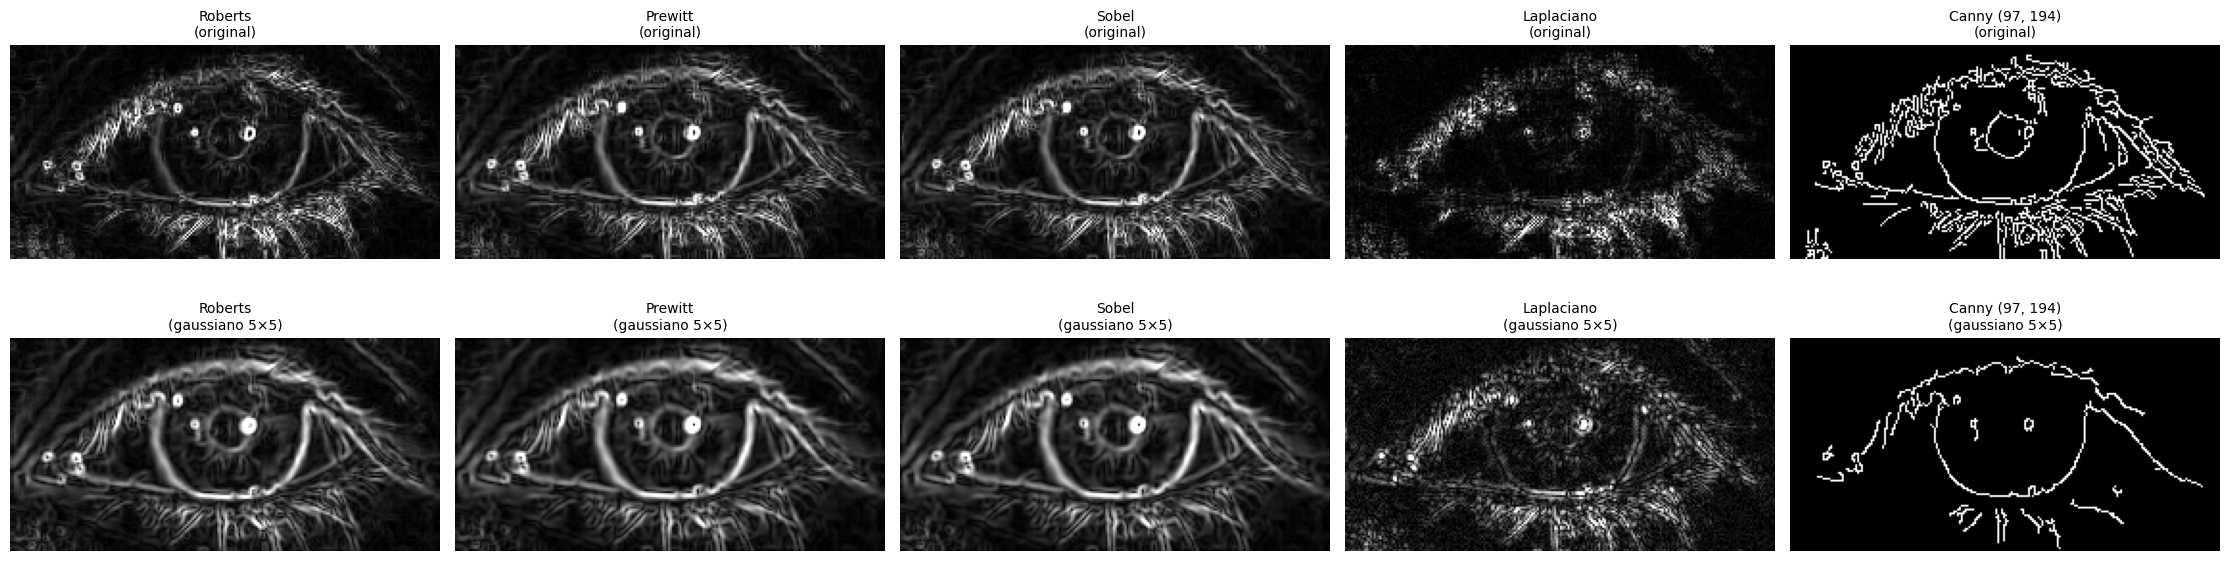

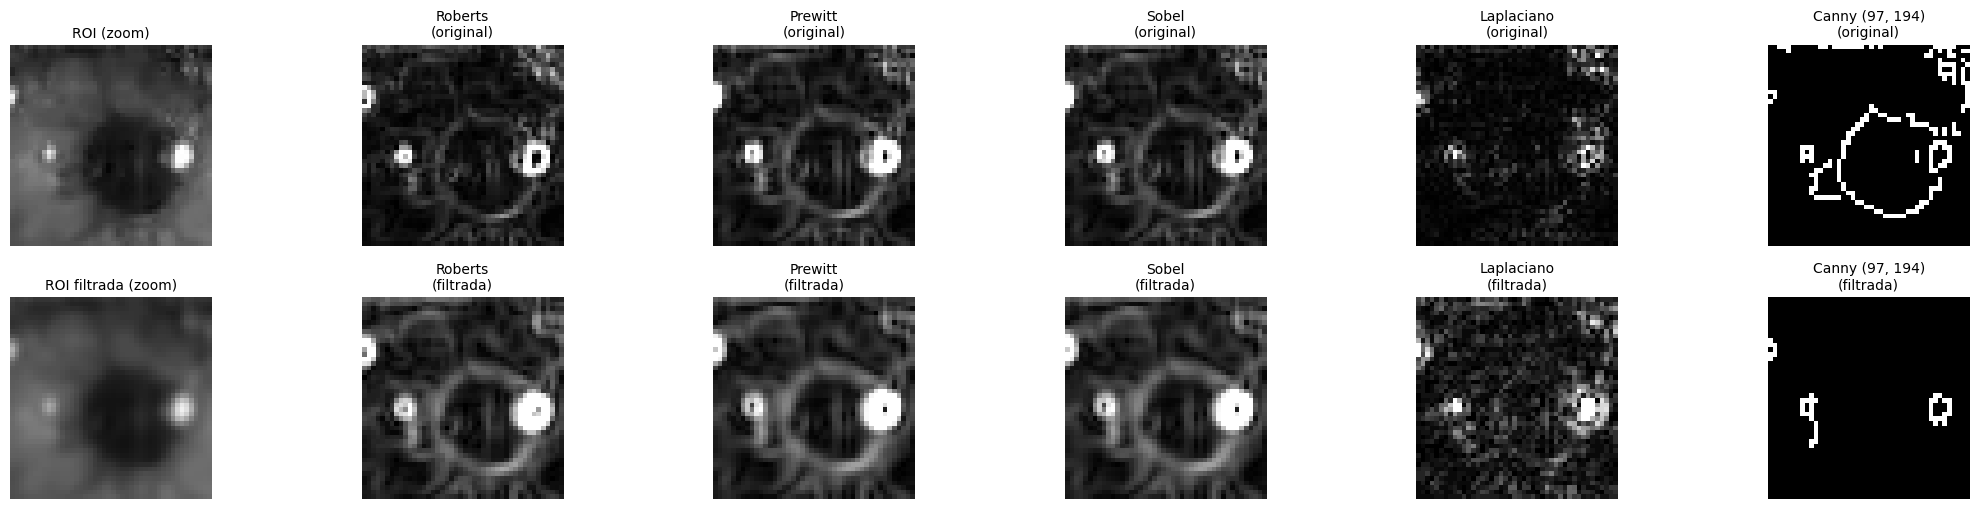

In [27]:
# detectar_bordes está en bordes_frecuencia.py 
# Les pasa los 5 filtros pasa altos que vimos en clase y devuelve un diccionario con las imágenes de bordes.
bordes_orig = bf.detectar_bordes(g)
bordes_filt = bf.detectar_bordes(g_filt)  # g_filt está filtrada con un gaussiano

# Fila 1: sobre la original. Fila 2: sobre la filtrada.
bf.mostrar({**{f"{k}\n(original)": v for k, v in bordes_orig.items()},
         **{f"{k}\n(gaussiano {KERNEL}×{KERNEL})": v for k, v in bordes_filt.items()}},
        filas=2, archivo="1_3_1_bordes.png", carpeta_res=carpeta_res)

# Zoom sobre la pupila para evaluar la CONTINUIDAD del contorno.
# {**a, **b} une dos diccionarios en uno.
bf.mostrar({"ROI (zoom)": bf.zoom(g, limites_zoom),
         **{f"{k}\n(original)": bf.zoom(v, limites_zoom) for k, v in bordes_orig.items()},
         "ROI filtrada (zoom)": bf.zoom(g_filt, limites_zoom),
         **{f"{k}\n(filtrada)": bf.zoom(v, limites_zoom) for k, v in bordes_filt.items()}},
        filas=2, archivo="1_3_1_bordes_zoom_pupila.png", tam=2.6, carpeta_res=carpeta_res)

**Análisis — continuidad del contorno pupilar:**

- **Roberts, Prewitt y Sobel** (calculan los bordes usando la primera derivada) 
  marcan el anillo pupila–iris, pero el elemento más brillante del mapa es el 
  reflejo del flash. Es el salto de intensidad más grande de la ROI. 
  Roberts (kernel 2×2) es el más ruidoso y fino mientras que como
  Prewitt y Sobel promedian con 3 filas, dan bordes más gruesos y continuos, aunque los tres filtros devuelven resultados bastante buenos.
- **Laplaciano** (segunda derivada): es el más sensible al ruido. Amplifica la
  textura del iris y de la piel incluso sobre la imagen filtrada y no da un
  contorno pupilar ni continuo ni reconocible.
- **Canny** sobre la original produce muchos fragmentos cortos (textura del iris,
  pestañas) y el contorno pupilar queda marcado con ellos: se lo puede distinguir muy bien
  como un círculo cerrado en el centro del ROI, de hecho es el que mejor resultado obtiene. 
  Sobre la filtrada, en cambio, el resultado es pésimo: al filtrar la imagen, la pupila queda tan suavizada que ni se detecta (el otro componente en esta imagen es el reflejo de la luz que aparece cerrado).
- **Conclusión:** suavizar antes de derivar mejora mucho la continuidad (la derivada
  amplifica el ruido de alta frecuencia; el gaussiano lo saca antes), pero hay que tener cuidado al suavizar antes de filtros como Canny, ya que se puede eliminar por completo la información que necesitamos.
  contorno y que persista solo la pupila habría que eliminar el reflejo primero (mediana, ver 1.2) 
  y/o completar el contorno con morfología o ajuste de círculo en el Módulo 2.

## 1.3.2 — Transformada de Fourier 2D (TFD-2D)

Toda imagen se puede escribir como una **suma de ondas planas** (senos y
cosenos 2D) de distintas frecuencias y orientaciones. La TFD-2D calcula, para
cada frecuencia $(u, v)$, un número complejo $F(u,v)$:

$$F(u,v) = \sum_{x}\sum_{y} f(x,y)\, e^{-j2\pi\left(\frac{ux}{M}+\frac{vy}{N}\right)}$$

- **Magnitud** $|F(u,v)|$: **cuánto** hay de esa onda (su amplitud).
- **Fase** $\angle F(u,v)$: **dónde** está desplazada esa onda (su posición).

Detalles de representación:
- `np.fft.fft2` pone la frecuencia (0,0) —el **promedio** de la imagen— en la esquina.
  `np.fft.fftshift` la lleva al **centro**: así bajas frecuencias = centro,
  altas = bordes del espectro.
- La magnitud varía entre valores enormes (el centro) y casi cero: se muestra en
  **escala logarítmica**, $\log(1 + |F|)$. El "+1" evita el $\log 0$.

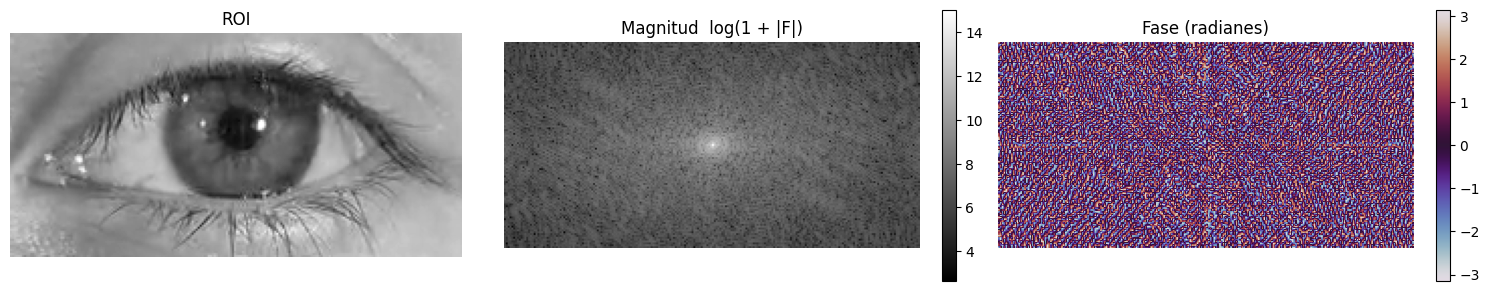

F(0,0) = 3425037 = suma de todos los píxeles (promedio 137.8 × 24864 píxeles)


In [28]:
F = np.fft.fft2(g.astype(np.float64))     # TFD-2D: aplica la transformada de Fourier a la ROI (g)
F_c = np.fft.fftshift(F)                  # frecuencia cero al centro (solo para mostrar)

magnitud = np.abs(F_c)                    # |F|: módulo del número complejo
fase = np.angle(F_c)                      # ángulo en radianes, entre -π y π

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))     # preparo todo para plotear las 3 imágenes: ROI, magnitud y fase
ax[0].imshow(g, cmap="gray", vmin=0, vmax=255)      # muestra la ROI en grises (g)
ax[0].set_title("ROI")
im1 = ax[1].imshow(np.log1p(magnitud), cmap="gray")   # log1p(x) = log(1 + x)
ax[1].set_title("Magnitud  log(1 + |F|)")
im2 = ax[2].imshow(fase, cmap="twilight")             # mapa cíclico: -π y π son el mismo ángulo
ax[2].set_title("Fase (radianes)")
fig.colorbar(im1, ax=ax[1], fraction=0.03)
fig.colorbar(im2, ax=ax[2], fraction=0.03)
for a in ax:
    a.axis("off")
plt.tight_layout()
fig.savefig(carpeta_res / "1_3_2_tfd_magnitud_fase.png", dpi=150)
plt.show()

print(f"F(0,0) = {F[0, 0].real:.0f} = suma de todos los píxeles "
      f"(promedio {F[0, 0].real / g.size:.1f} × {g.size} píxeles)")

**Análisis:**

- La **magnitud** está muy concentrada en el **centro** (bajas frecuencias) porque la mayor
  parte de la imagen son variaciones lentas (piel, esclerótica, iris). Los detalles
  finos (pestañas, borde pupilar, textura) que son las frecuencias altas, tienen menos
  energía. El valor del centro, $F(0,0)$, es la suma de todos los píxeles.
- La **cruz** horizontal y vertical que pasa por el centro no es una estructura del
  ojo. La TFD supone que la imagen se repite periódicamente y el salto entre el
  borde izquierdo y el derecho (y entre el de arriba y el de abajo) actúa como un
  borde vertical/horizontal.
- La **fase** parece ruido aleatorio a simple vista, no se puede "leer", pero es la que lleva la información de **dónde** está cada cosa.

### Reconstrucción con solo magnitud, solo fase y cruzada

Con la **transformada inversa** (`np.fft.ifft2`) se vuelve a la imagen. Si
antes "rompemos" una de las dos partes, vemos cuál lleva la información:

- **Solo magnitud:** $F' = |F|\cdot e^{j0}$ (todas las fases en cero).
- **Solo fase:** $F' = 1\cdot e^{j\angle F}$ (todas las magnitudes iguales a 1).
- **Cruce:** magnitud de una imagen A con la fase de otra imagen B, y al revés.

Como imagen B usamos un texto, del mismo tamaño que
la ROI --> es muy distinta del ojo, así que en el cruce se reconoce fácilmente.

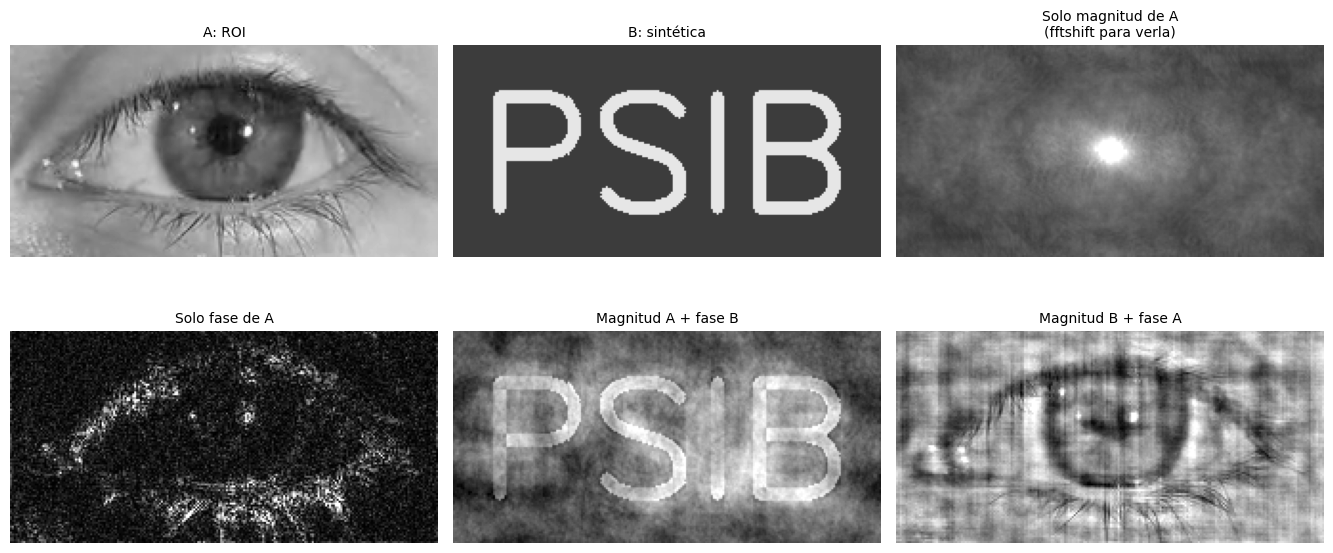

Error máximo al reconstruir con magnitud y fase: 2.27e-13 niveles de gris


In [29]:

# Imagen B sintética: texto blanco grande sobre fondo gris, mismo tamaño que g
B = np.full(g.shape, 60, dtype=np.uint8)          # matriz llena de 60 (gris oscuro)
escala = g.shape[0] / 40                           # tamaño de letra proporcional al alto
(tw, th), _ = cv2.getTextSize(TEXTO_B, cv2.FONT_HERSHEY_SIMPLEX, escala, 3)  # medidas del texto
cv2.putText(B, TEXTO_B, ((g.shape[1] - tw) // 2, (g.shape[0] + th) // 2),   # centrado
            cv2.FONT_HERSHEY_SIMPLEX, escala, 230, thickness=max(2, int(escala * 2)))
FB = np.fft.fft2(B.astype(np.float64))

# Magnitudes y fases (sin fftshift (que ponía el 0,0 en el centro): 
# para reconstruir hay que usar el orden original)
magA, fasA = np.abs(F), np.angle(F)
magB, fasB = np.abs(FB), np.angle(FB)

solo_mag = bf.reconstruir(magA, np.zeros_like(fasA))   # fase = 0 en todas las frecuencias
solo_fase = bf.reconstruir(np.ones_like(magA), fasA)   # magnitud = 1 en todas
magA_faseB = bf.reconstruir(magA, fasB)
magB_faseA = bf.reconstruir(magB, fasA)

bf.mostrar({"A: ROI": g,
         "B: sintética": B,
         "Solo magnitud de A\n(fftshift para verla)": bf.a_0_255(np.fft.fftshift(solo_mag)),
         "Solo fase de A": bf.a_0_255(solo_fase - solo_fase.mean()),
         "Magnitud A + fase B": bf.a_0_255(magA_faseB - magA_faseB.min()),
         "Magnitud B + fase A": bf.a_0_255(magB_faseA - magB_faseA.min())},
        filas=2, archivo="1_3_2_reconstrucciones.png", carpeta_res=carpeta_res)

# Verificación: con magnitud Y fase originales se recupera la imagen exacta.
exacta = bf.reconstruir(magA, fasA)
print(f"Error máximo al reconstruir con magnitud y fase: {np.abs(exacta - g).max():.2e} niveles de gris")

**Análisis**

- **Solo magnitud:** no se reconoce nada del ojo: queda una mancha brillante en el
  centro (con todas las fases en cero, todas las ondas "arrancan" en el mismo punto,
  el origen, y se suman ahí). La magnitud dice **cuánto** hay de cada frecuencia,
  pero no **dónde**.
- **Solo fase:** se reconocen los **bordes** del ojo (párpados, pestañas, contorno del
  iris). Al poner todas las magnitudes en 1, las bajas frecuencias pierden su peso
  y quedan resaltadas las altas --> se ve como un detector de bordes.
- **Cruces:** "magnitud del ojo + fase del texto" muestra el **texto PSIB**, y
  "magnitud del texto + fase del ojo" muestra el **ojo**. La imagen reconstruida
  siempre se parece a la que aportó la **fase** --> **la fase tiene la información estructural**.
- **Conclusión:** cualquier filtrado en frecuencia **no debe tocar la fase**
  porque si la fase se altera, la estructura de la pupila se deforma.

## 1.3.3 — Densidad Espectral de Potencia (PSD)

$\mathrm{PSD}(u,v) = |F(u,v)|^2$: cuánta **energía** (potencia) tiene la imagen
en cada frecuencia. Para comparar antes y después del filtrado espacial
calculamos además el **perfil radial**: el promedio de la PSD sobre anillos de
igual distancia al centro, es decir, la energía en función de la frecuencia
**sin importar la orientación**. Así se obtiene una curva 1D fácil de comparar.

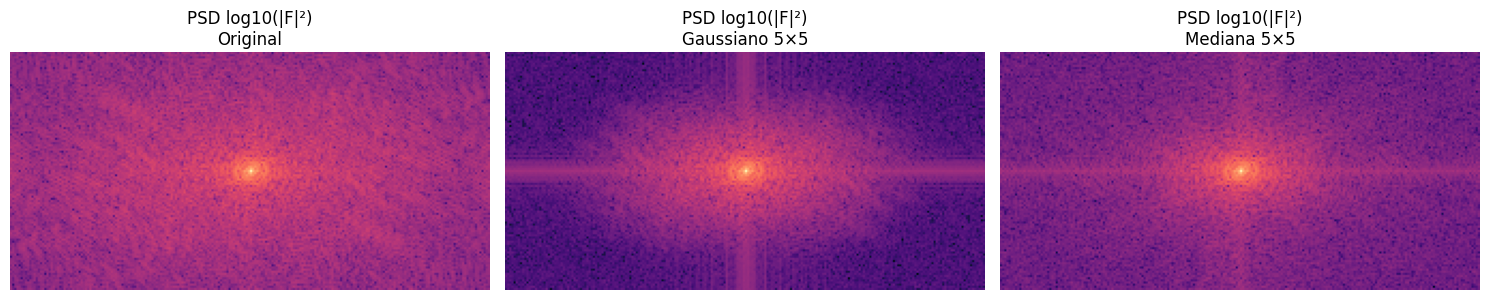

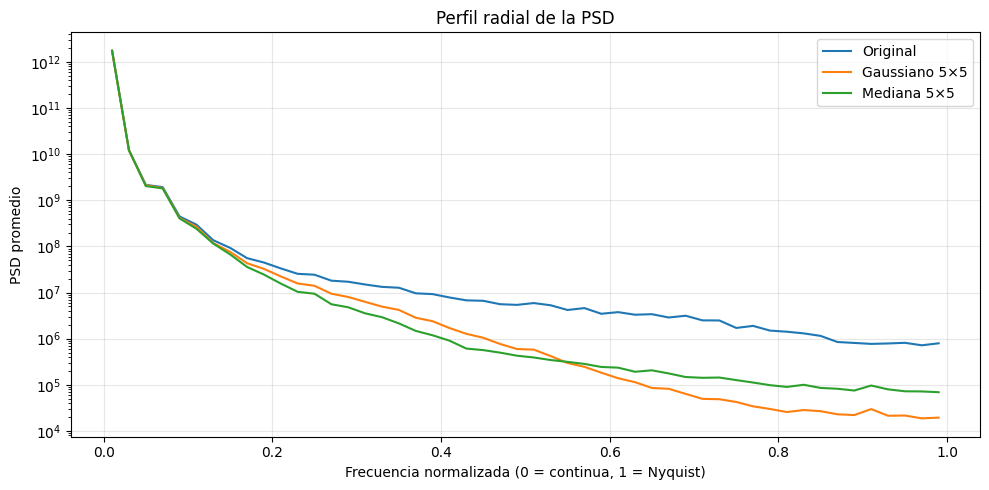

Original         energía en frecuencias altas (> 0.5): 3.09 %
Gaussiano 5×5    energía en frecuencias altas (> 0.5): 0.13 %
Mediana 5×5      energía en frecuencias altas (> 0.5): 0.23 %


In [30]:
g_mediana = cv2.medianBlur(g, KERNEL)   # Le pasamos el filtro de mediana a la ROI original (g) para comparar con el gaussiano (g_filt)

versiones = {
    "Original": g,
    f"Gaussiano {KERNEL}×{KERNEL}": g_filt, # El gaussiano ya lo teniamos de antes
    f"Mediana {KERNEL}×{KERNEL}": g_mediana
}

# ---------------------------------------------------------
# FIGURA 1: Las tres PSD
# ---------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

P_original = bf.psd(g)
vmax = np.log10(P_original.max() + 1)

for i, (nombre, im) in enumerate(versiones.items()):
    P = bf.psd(im)

    ax[i].imshow(np.log10(P + 1), cmap="magma", vmin=0, vmax=vmax)
    ax[i].set_title(f"PSD log10(|F|²)\n{nombre}")
    ax[i].axis("off")

plt.tight_layout()
fig.savefig(carpeta_res / "1_3_3_psd.png", dpi=150)
plt.show()

# ---------------------------------------------------------
# FIGURA 2: Perfil radial de las tres PSD --> la energía en función de la frecuencia
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))

for nombre, im in versiones.items():
    P = bf.psd(im)          # Devuelve la |TFD|² con la frecuencia cero en el medio (está en bordes_frecuencia.py)
    f_rad, perfil = bf.perfil_radial(P)     # Devuelve el promedio de la PSD sobre círculos concéntricos (perfil radial) 
    #y la frecuencia normalizada correspondiente

    ax.semilogy(f_rad, perfil, label=nombre)

ax.set_xlabel("Frecuencia normalizada (0 = continua, 1 = Nyquist)")
ax.set_ylabel("PSD promedio")
ax.set_title("Perfil radial de la PSD")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(carpeta_res / "1_3_3_perfil_radial.png", dpi=150)
plt.show()

# ---------------------------------------------------------
# Energía en frecuencias altas --> quiero saber que porcentaje de la energía total está en frecuencias altas (mayores a 0.5)
# ---------------------------------------------------------
for nombre, im in versiones.items():
    # Calculamos las PSD
    P = bf.psd(im)
    Nf, Nc = P.shape  # Dimensiones de la matríz P

    v, u = np.mgrid[0:Nf, 0:Nc]     # Coordenadas de cada píxel (v = filas, u = columnas)
    rad = np.hypot((u - Nc // 2) / (Nc / 2),    # Calcula la distancia de cada píxel al centro (frecuencia cero) y la normaliza a [0, 1]
                   (v - Nf // 2) / (Nf / 2))

    P_sin_dc = P.copy()
    P_sin_dc[Nf // 2, Nc // 2] = 0          # Eliminamos la componente DC (frecuencia cero) para que no domine el cálculo de energía

    alta = P_sin_dc[rad > 0.5].sum() / P_sin_dc.sum()      # Calcula la fracción de energía > 0.5 (¡lo que nos importa!)

    print(f"{nombre:16s} energía en frecuencias altas (> 0.5): {100 * alta:.2f} %")


**Análisis:**

- En el perfil radial las tres curvas coinciden en las **bajas** frecuencias (≤ ≈0,15
  de Nyquist): ninguno de los filtros cambia la forma general del ojo.
- En las **altas** frecuencias los filtrados caen bastante por debajo de la original
  (casi un orden de magnitud a partir de ≈0,4 Nyquist): la energía por encima de
  0,4 Nyquist baja de ≈2 % a ≈0,25 % (gaussiano) y ≈0,35 % (mediana). Ambos son
  **pasa-bajos**: eliminan detalle fino y ruido.
- El gaussiano atenúa de forma suave y monótona (su respuesta en frecuencia es otra
  gaussiana). La mediana no es lineal y conserva algo más de energía alta porque **preserva los bordes
  abruptos**, que son justamente contenido de alta frecuencia.

## 1.3.4 — Filtrado en frecuencia: pasa-bajos y pasa-altos

Por el **teorema de convolución**, convolucionar en el espacio equivale a
**multiplicar** en frecuencia: $g * h \;\leftrightarrow\; G\cdot H$. Entonces
filtrar en frecuencia es: TFD → multiplicar por una máscara $H(u,v)$ → TFD inversa.

Diseñamos dos tipos de máscara, con $D$ = distancia (normalizada) al centro:

- **Ideal:** $H = 1$ si $D \le D_0$, 0 si no. Corte abrupto.
- **Gaussiano:** $H = e^{-D^2/(2D_0^2)}$. Corte suave.
- **Pasa-altos** = $1 - $ pasa-bajos.

Además armamos un **pasa-bajos gaussiano equivalente** al filtro gaussiano
espacial de σ = `SIGMA` (la TFD de una gaussiana de desvío σ es otra gaussiana de
desvío $\frac{1}{2\pi\sigma}$ ciclos/píxel) para comparar ambos caminos.

Ahora vamos a hacer esto:
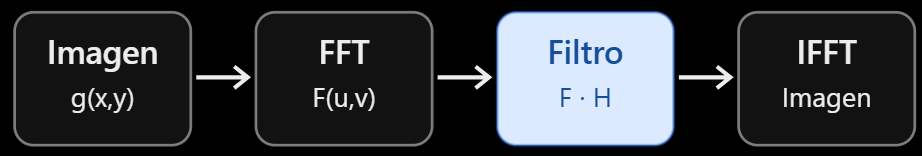

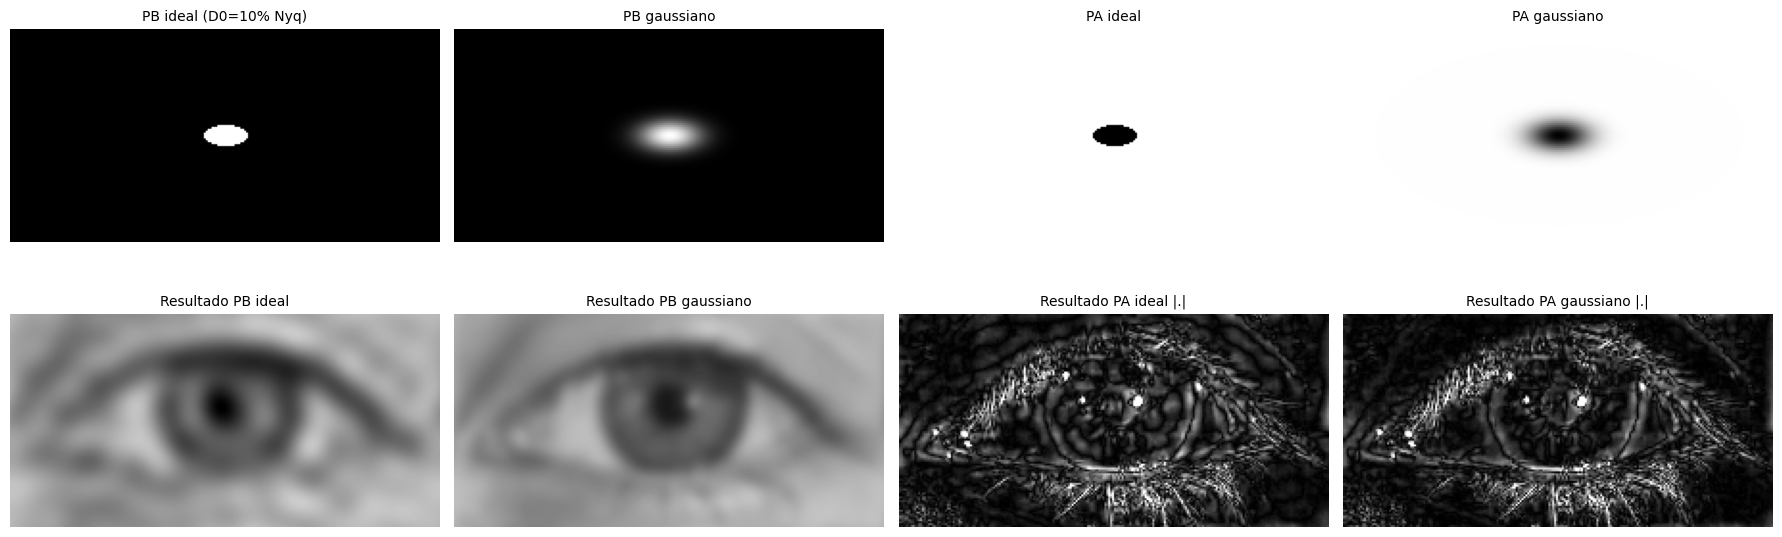

In [31]:
Nf, Nc = g.shape
v, u = np.mgrid[0:Nf, 0:Nc]     # Coordenadas de cada píxel (v = filas, u = columnas)
# Frecuencia de cada punto del espectro centrado, en CICLOS POR PÍXEL
# (va de -0.5 a 0.5; 0.5 = Nyquist, la frecuencia más alta representable).
fu = (u - Nc // 2) / Nc     # frecuencia horizontal (columnas) normalizada a [-0.5, 0.5]
fv = (v - Nf // 2) / Nf     # frecuencia vertical (filas) normalizada a [-0.5, 0.5]
D = np.hypot(fu, fv)                     # distancia al centro en ciclos/píxel
# f de Nyquist es 0.5 ciclos/píxel, así que D0 = CORTE * 0.5 ciclos/píxel
D0 = CORTE * 0.5                         # el CORTE está definido en config como 0,1 (al momento de la entrega) 
# --> D0 = 0,05 ciclos/píxel (5% de Nyquist)

H_pb_ideal = (D <= D0).astype(np.float64)         # Pasa bajos ideal (se queda con las frecuencias menores a D0, pasa a 1; las mayores a D0 pasan a 0)
H_pb_gauss = np.exp(-D ** 2 / (2 * D0 ** 2))    # En el pasa bajos gaussiano, las frecuencias bajas se mantienen y las altas se atenúan progresivamente (no se cortan bruscamente como en el ideal).
H_pa_ideal = 1 - H_pb_ideal         # Para los pasa altos hacemos 1 - el pasa bajos que corresponda
H_pa_gauss = 1 - H_pb_gauss

# Gaussiano EQUIVALENTE al espacial: desvío en frecuencia = 1 / (2π·SIGMA)
H_equiv = np.exp(-D ** 2 / (2 * (1 / (2 * np.pi * SIGMA)) ** 2))    # Su comportamiento es similar al gaussiano espacial, pero en frecuencia. 
# La relación entre sigma espacial y sigma en frecuencia es 1 / (2π·SIGMA).

# Aplicamos los filtros sobre la roi
pb_ideal = bf.filtrar_frecuencia(g, H_pb_ideal)
pb_gauss = bf.filtrar_frecuencia(g, H_pb_gauss)
pa_ideal = bf.filtrar_frecuencia(g, H_pa_ideal)
pa_gauss = bf.filtrar_frecuencia(g, H_pa_gauss)
equiv = bf.filtrar_frecuencia(g, H_equiv)

# Fila 1: máscaras. Fila 2: resultados.
# Se muestran con a_0_255 (valor absoluto).
bf.mostrar({f"PB ideal (D0={CORTE:.0%} Nyq)": (H_pb_ideal * 255).astype(np.uint8),
         "PB gaussiano": (H_pb_gauss * 255).astype(np.uint8),
         "PA ideal": (H_pa_ideal * 255).astype(np.uint8),
         "PA gaussiano": (H_pa_gauss * 255).astype(np.uint8),
         "Resultado PB ideal": np.clip(pb_ideal, 0, 255).astype(np.uint8),
         "Resultado PB gaussiano": np.clip(pb_gauss, 0, 255).astype(np.uint8),
         "Resultado PA ideal |.|": bf.a_0_255(pa_ideal),
         "Resultado PA gaussiano |.|": bf.a_0_255(pa_gauss)},
        filas=2, archivo="1_3_4_filtros_frecuencia.png", carpeta_res=carpeta_res)

**Análisis:**

- **Pasa-bajos:** con un corte en el 10 % de Nyquist ambos desenfocan mucho (solo
  queda la forma general del ojo; la pupila sigue visible como mancha oscura). El
  **ideal** produce **ringing** (efecto Gibbs): ondulaciones paralelas a los bordes
  fuertes (párpado, borde pupilar). Se debe a que el corte abrupto en frecuencia
  equivale a convolucionar con una función tipo *sinc*, que tiene lóbulos laterales
  que "rebotan". El **gaussiano** no tiene ringing porque su transformada es otra
  gaussiana, sin lóbulos.
- **Pasa-altos:** dejan solo los cambios rápidos (bordes y textura), como los
  detectores de bordes vistos en clase. El ideal vuelve a mostrar ondulaciones alrededor de los bordes;
  el gaussiano da bordes más limpios.
- La máscara se ve **elíptica** porque la ROI no es cuadrada: el corte es un círculo
  en frecuencia real (ciclos/píxel), pero el eje horizontal tiene más muestras (224)
  que el vertical (111).

### Comparación con el filtrado espacial (y PSNR / SSIM)

**¿Cómo cuantificar la calidad de una imagen respecto de la original?**

- **PSNR (peak signal-to-noise ratio)** = $10\log_{10}\!\left(\dfrac{255^2}{\mathrm{MSE}}\right)$ dB, con
  MSE = error cuadrático medio píxel a píxel. Más alto = más parecida (>30 dB muy parecida).
- **SSIM (Structural Similarity Indez Measure)** (−1 a 1): compara luminancia, contraste y **estructura** en ventanas
  locales; se acerca más a la percepción humana. 1 = idéntica.

Comparamos cada resultado contra la ROI original, y el gaussiano en frecuencia
contra el gaussiano espacial (si el teorema de convolución se cumple, deberían
ser prácticamente iguales).

Imagen comparada con la ROI original         PSNR [dB]   SSIM
--------------------------------------------------------------
Gaussiano espacial 5×5 σ=1.0                      30.6  0.905
Mediana espacial 5×5                              27.9  0.820
Media espacial 5×5                                27.8  0.804
Gaussiano en frecuencia (equivalente)             30.5  0.901
PB ideal en frecuencia (10%)                      24.4  0.604
PB gaussiano en frecuencia (10%)                  25.5  0.688

Gaussiano frecuencia vs espacial: PSNR = 48.1 dB, SSIM = 0.998


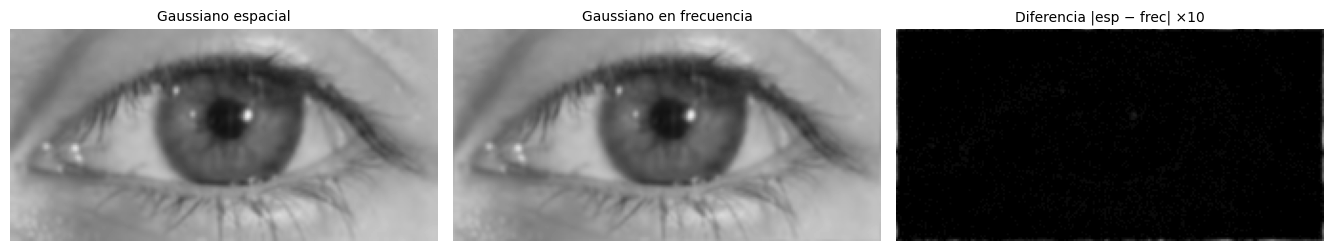

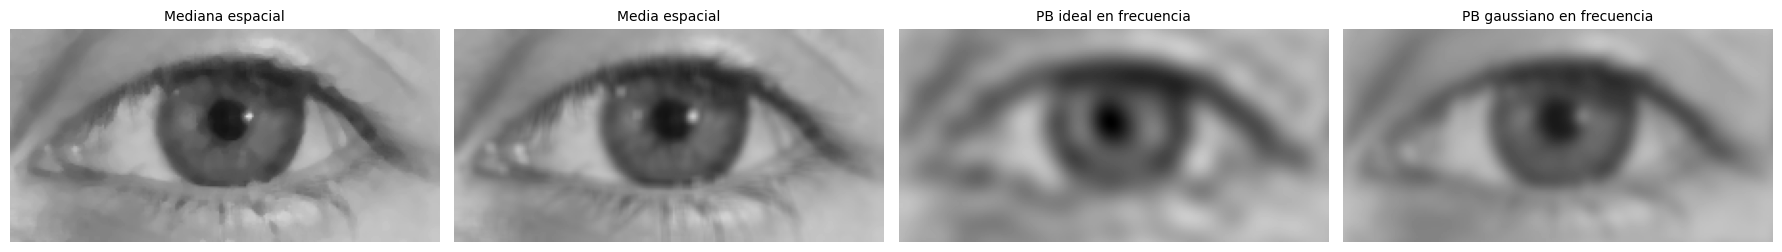

In [32]:
# Todos los filtros que aplicamos sobre la ROI (g) se comparan con la ROI original, usando PSNR y SSIM.
candidatos = {
    f"Gaussiano espacial {KERNEL}×{KERNEL} σ={SIGMA}": g_filt,
    f"Mediana espacial {KERNEL}×{KERNEL}": g_mediana,
    f"Media espacial {KERNEL}×{KERNEL}": cv2.blur(g, (KERNEL, KERNEL)),   # Aplica el filtro de media (promedio) sobre la ROI original (g)
    "Gaussiano en frecuencia (equivalente)": bf.a_uint8(equiv),
    f"PB ideal en frecuencia ({CORTE:.0%})": bf.a_uint8(pb_ideal),
    f"PB gaussiano en frecuencia ({CORTE:.0%})": bf.a_uint8(pb_gauss),
}

print(f"{'Imagen comparada con la ROI original':44s} {'PSNR [dB]':>9s} {'SSIM':>6s}")
print("-" * 62)
for nombre, im in candidatos.items():
    # acá se calcula el PSNR y SSIM entre la ROI original (g) y cada imagen filtrada (im)
    v_psnr = peak_signal_noise_ratio(g, im, data_range=255)
    v_ssim = structural_similarity(g, im, data_range=255)
    print(f"{nombre:44s} {v_psnr:9.1f} {v_ssim:6.3f}")

# Gaussiano en frecuencia vs gaussiano espacial: dan MUY PARECIDOS
eq = candidatos["Gaussiano en frecuencia (equivalente)"]
print(f"\nGaussiano frecuencia vs espacial: PSNR = "
      f"{peak_signal_noise_ratio(g_filt, eq, data_range=255):.1f} dB, "
      f"SSIM = {structural_similarity(g_filt, eq, data_range=255):.3f}")

bf.mostrar({
    "Gaussiano espacial": g_filt,
    "Gaussiano en frecuencia": eq,
    # Se restan los valores de cada píxel entre el gaussiano espacial y el gaussiano en frecuencia, 
    # se multiplica por 10 para que se vea mejor y se recorta a [0, 255] para que sea una imagen válida.
    "Diferencia |esp − frec| ×10":     
    np.clip(10 * np.abs(g_filt.astype(int) - eq.astype(int)), 0, 255).astype(np.uint8)},
    archivo="1_3_4_espacial_vs_frecuencia.png", carpeta_res=carpeta_res)

bf.mostrar({"Mediana espacial": g_mediana, 
            "Media espacial": cv2.blur(g, (KERNEL, KERNEL)),
            "PB ideal en frecuencia": bf.a_uint8(pb_ideal),
            "PB gaussiano en frecuencia": bf.a_uint8(pb_gauss)}, 
archivo="1_3_4_mediana_vs_media.png", carpeta_res=carpeta_res)

**Análisis:**

- El **gaussiano en frecuencia** equivalente y el **gaussiano espacial** dan
  prácticamente la misma imagen (≈43 dB, SSIM ≈ 0,997 entre ellos): se verifica el
  **teorema de convolución**.
- **¿Cuándo conviene cada uno?** Para kernels chicos (3×3, 5×5) el espacial es más
  simple y rápido. En frecuencia el costo no depende del tamaño del filtro y permite
  diseñar cortes exactos (ideal, gaussiano, pasa-banda), a cambio del ringing en el
  caso ideal y de los artefactos de borde.
- Entre los filtros espaciales, el gaussiano 5×5 es el que más se parece a la
  original (≈33 dB, SSIM ≈ 0,93): suaviza poco. Los pasa-bajos en frecuencia al 10 %
  son mucho más agresivos (≈26–27 dB), y el ideal es peor que el gaussiano por el
  ringing.
- **Cómo cuantificar la calidad:** PSNR mide error píxel a píxel; SSIM mide
  conservación de estructura y se correlaciona mejor con lo que vemos. Conviene
  reportar ambos. Nota: acá la "referencia" es la propia original, así que ambos
  miden **cuánto se alejó** cada filtro de ella. Para analizar cuanto ruido sacó cada filtro
  ir al punto 1.2.4, donde agregamos ruido conocido y luego filtramos.